# Milestone 2 Computational Analysis
## E-Commerce Customer Satisfaction —— An Operational Analysis of Order Fulfillment

This notebook provides the computational evidence supporting the Milestone 2 dossier, including data quality, missingness, dependence
diagnostics, exploratory analysis, leakage checks, and baselines.

I run 01_merge.ipynb first to generate the order-level dataset. 

## 1. Environment and Data Loading

In [3]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 80)

cwd = Path.cwd()

if (cwd / "data" / "derived").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "derived").is_dir():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Cannot find data/derived. Run 01_merge.ipynb first "
        "and launch Jupyter from the project root "
        "or the notebooks folder.")

DERIVED_DIR = PROJECT_ROOT / "data" / "derived"
RAW_DIR = PROJECT_ROOT / "data" / "raw"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURE_DIR = PROJECT_ROOT / "figures"

for folder in [TABLE_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

MERGED_PATH = DERIVED_DIR / "olist_orders_merged.csv"
INVENTORY_PATH = DERIVED_DIR / "merged_column_inventory.csv"

for path in [MERGED_PATH, INVENTORY_PATH]:
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {path.name}. Run 01_merge.ipynb first.")

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Project root:", PROJECT_ROOT)

Python: 3.13.5
pandas: 2.3.2
NumPy: 2.3.1
Project root: /Users/bishanzhou/Documents/wustl_life/practicum/olist_capstone


In [7]:
column_inventory = pd.read_csv(INVENTORY_PATH)

dtype_lookup = column_inventory.set_index(
    "column"
)["pandas_dtype"]

datetime_columns = dtype_lookup[
    dtype_lookup.str.startswith("datetime64")
].index.tolist()

boolean_columns = dtype_lookup[
    dtype_lookup.isin(["bool", "boolean"])
].index.tolist()

nullable_integer_columns = dtype_lookup[
    dtype_lookup.eq("Int64")
].index.tolist()

text_columns = [
    "order_id",
    "customer_id",
    "customer_unique_id",
    "customer_zip_code_prefix",
    "review_id_latest",
    "product_ids",
    "seller_ids",
    "seller_zip_code_prefixes",
]

read_dtypes = {
    column: "string"
    for column in text_columns
    if column in dtype_lookup.index
}

read_dtypes.update({
    column: "boolean"
    for column in boolean_columns
})

read_dtypes.update({
    column: "Int64"
    for column in nullable_integer_columns
})

# Read timestamp columns as text first.
read_dtypes.update({
    column: "string"
    for column in datetime_columns})

df = pd.read_csv(
    MERGED_PATH,
    dtype=read_dtypes,)

date_parsing_results = []

for column in datetime_columns:
    original = df[column].copy()

    parsed = pd.to_datetime(
        original,
        format="ISO8601",
        errors="coerce",)

    failed = original.notna() & parsed.isna()
    date_parsing_results.append({
        "column": column,
        "original_missing": int(original.isna().sum()),
        "parse_failures": int(failed.sum()),})

    if failed.any():
        raise ValueError(
            f"Unrecognized dates in {column}: "
            f"{original.loc[failed].head().tolist()}")
    df[column] = parsed

date_parsing_summary = pd.DataFrame(date_parsing_results)
display(date_parsing_summary)

date_parsing_summary.to_csv(
    TABLE_DIR / "merged_timestamp_parsing_checks.csv",
    index=False,)

print("Loaded rows:", len(df))
print("Loaded columns:", df.shape[1])

display(df.head())

,column,original_missing,parse_failures
0,order_purchase_timestamp,0,0
1,order_approved_at,160,0
2,order_delivered_carrier_date,1783,0
3,order_delivered_customer_date,2965,0
4,order_estimated_delivery_date,0,0
5,shipping_limit_earliest,775,0
6,shipping_limit_latest,775,0
7,review_creation_date,768,0
8,review_answer_timestamp,768,0


Loaded rows: 99441
Loaded columns: 74


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,customer_latitude,customer_longitude,customer_geo_unique_row_count,item_count,product_count,seller_count,category_count,items_price_total,freight_value_total,primary_product_category,product_categories,product_categories_english,product_ids,seller_ids,shipping_limit_earliest,shipping_limit_latest,product_weight_g_mean,product_volume_cm3_mean,item_missing_category_count,item_missing_weight_count,item_missing_volume_count,primary_product_category_english,payment_record_count,payment_value_total,payment_types,payment_installments_max,payment_installments_mean,review_record_count,review_score_min,review_score_max,review_score_mean,review_id_latest,review_score_latest,review_creation_date,review_answer_timestamp,review_scores_conflict,seller_states,seller_cities,seller_zip_code_prefixes,seller_customer_distance_km_item_mean,seller_customer_distance_km_max,item_distance_observed_count,approval_duration_days,seller_handling_duration_days,carrier_delivery_duration_days,total_delivery_duration_days,promised_delivery_duration_days,delivery_delay_days,delivered_late,freight_to_items_value_ratio,order_purchase_month,has_item_records,has_payment_records,has_review,has_valid_review_score,is_delivered,eligible_delivered_reviewed,dissatisfied_latest,dissatisfied_any_review,negative_duration_flag,review_before_delivery,distance_coverage_ratio
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,03149,sao paulo,SP,-23.575816,-46.587303,16.0,1.0,1.0,1.0,1.0,29.99,8.72,utilidades_domesticas,utilidades_domesticas,housewares,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,2017-10-06 11:07:15,500.0,1976.0,0.0,0.0,0.0,housewares,3.0,38.71,credit_card|voucher,1.0,1.0,1.0,4.0,4.0,4.0,a54f0611adc9ed256b57ede6b6eb5114,4.0,2017-10-11,2017-10-12 03:43:48,False,SP,maua,09350,18.676602,18.676602,1.0,0.007431,2.366493,6.062650,8.436574,15.544063,-8,False,0.290764,2017-10,True,True,True,True,True,True,False,False,False,False,1.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,-12.126533,-45.008244,14.0,1.0,1.0,1.0,1.0,118.70,22.76,perfumaria,perfumaria,perfumery,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,2018-07-30 03:24:27,400.0,4693.0,0.0,0.0,0.0,perfumery,1.0,141.46,boleto,1.0,1.0,1.0,4.0,4.0,4.0,8d5266042046a06655c8db133d120ba5,4.0,2018-08-08,2018-08-08 18:37:50,False,SP,belo horizonte,31570,861.069892,861.069892,1.0,1.279745,0.462882,12.039410,13.782037,19.137766,-6,False,0.191744,2018-07,True,True,True,True,True,True,False,False,False,False,1.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,-16.744472,-48.514624,25.0,1.0,1.0,1.0,1.0,159.90,19.22,automotivo,automotivo,auto,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,2018-08-13 08:55:23,420.0,9576.0,0.0,0.0,0.0,auto,1.0,179.12,credit_card,3.0,3.0,1.0,5.0,5.0,5.0,e73b67b67587f7644d5bd1a52deb1b01,5.0,2018-08-18,2018-08-22 19:07:58,False,SP,guariba,14840,514.535809,514.535809,1.0,0.011505,0.204595,9.178113,9.394213,26.639711,-18,False,0.120200,2018-08,True,True,True,True,True,True,False,False,False,False,1.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,20

In [9]:
assert df["order_id"].notna().all()
assert df["order_id"].is_unique

eligible_mask = (
    df["order_status"].eq("delivered")
    & df["review_score_latest"].between(1, 5))

assert eligible_mask.equals(
    df["eligible_delivered_reviewed"].astype(bool)
), "The stored eligibility flag differs from the documented rule."

analysis_df = df.loc[eligible_mask].copy()

# Define the observed outcome explicitly.
analysis_df["y"] = (
    analysis_df["review_score_latest"].le(2).astype("int64"))

overview = pd.DataFrame([
    {"metric": "All orders", "value": len(df)},
    {
        "metric": "Delivered orders",
        "value": int(df["order_status"].eq("delivered").sum()),
    },
    {
        "metric": "Preliminary analytical orders",
        "value": len(analysis_df),
    },
    {
        "metric": "Low-review orders",
        "value": int(analysis_df["y"].sum()),
    },
    {
        "metric": "Low-review rate (%)",
        "value": round(100 * analysis_df["y"].mean(), 2),
    },
])

display(overview)

overview.to_csv(
    TABLE_DIR / "analysis_overview.csv",
    index=False,)

,metric,value
0,All orders,99441.00
1,Delivered orders,96478.00
2,Preliminary analytical orders,95832.00
3,Low-review orders,12273.00
4,Low-review rate (%),12.81


The preliminary analytical cohort contains delivered orders with valid selected review scores. This is not yet the final cleaned sample.
All orders remain available in df for missingness and selection checks, analysis_df contains the preliminary cohort, with y = 1 for scores of 1–2 and y = 0 for scores of 3–5.

## 2. Missingness and Review Availability

We compare missing measurements in all orders and the preliminary delivered-and-reviewed cohort.

We also compare delivered orders with and without valid review scores. Observed differences may indicate selection, but do not establish
the mechanism causing missing reviews.

In [11]:
MISSINGNESS_FIELDS = {
    "order_approved_at": "Approval timestamp",
    "order_delivered_carrier_date": "Carrier handoff timestamp",
    "order_delivered_customer_date": "Customer delivery timestamp",
    "review_score_latest": "Selected review score",
    "item_count": "Item records",
    "payment_record_count": "Payment records",
    "primary_product_category": "Primary product category",
    "product_weight_g_mean": "Mean observed product weight",
    "product_volume_cm3_mean": "Mean derived product volume",
    "customer_latitude": "Representative customer coordinates",
    "seller_customer_distance_km_item_mean": "Mean customer-seller distance",}

missingness_rows = []

for column, label in MISSINGNESS_FIELDS.items():
    all_missing = int(df[column].isna().sum())
    cohort_missing = int(analysis_df[column].isna().sum())

    missingness_rows.append({
        "field": label,
        "all_orders_missing": all_missing,
        "all_orders_missing_pct": 100 * all_missing / len(df),
        "cohort_missing": cohort_missing,
        "cohort_missing_pct": 100 * cohort_missing / len(analysis_df),})

missingness_summary = pd.DataFrame(missingness_rows)
display(missingness_summary.round(2))
missingness_summary.to_csv(
    TABLE_DIR / "missingness_summary.csv",
    index=False,)

,field,all_orders_missing,all_orders_missing_pct,cohort_missing,cohort_missing_pct
0,Approval timestamp,160,0.16,14,0.01
1,Carrier handoff timestamp,1783,1.79,2,0.00
2,Customer delivery timestamp,2965,2.98,8,0.01
3,Selected review score,768,0.77,0,0.00
4,Item records,775,0.78,0,0.00
5,Payment records,1,0.00,1,0.00
6,Primary product category,2164,2.18,1324,1.38
7,Mean observed product weight,791,0.80,16,0.02
8,Mean derived product volume,791,0.80,16,0.02
9,Representative customer coordinates,278,0.28,263,0.27


In [13]:
delivered_df = df.loc[
    df["order_status"].eq("delivered")].copy()

delivered_df["review_available"] = (
    delivered_df["review_score_latest"].between(1, 5))

review_group_rows = []

for available, group in delivered_df.groupby("review_available"):
    observed_lateness = group["delivered_late"].dropna()
    late_count = int(observed_lateness.sum())

    review_group_rows.append({
        "group": (
            "With valid review score"
            if available
            else "Without valid review score"
        ),
        "orders": len(group),
        "observed_delivery_duration_n": int(
            group["total_delivery_duration_days"].notna().sum()
        ),
        "median_delivery_days": (
            group["total_delivery_duration_days"].median()
        ),
        "median_item_value_brl": group["items_price_total"].median(),
        "median_freight_brl": group["freight_value_total"].median(),
        "observed_delivery_timing_n": len(observed_lateness),
        "late_orders": late_count,
        "late_rate_pct": (
            100 * late_count / len(observed_lateness)
            if len(observed_lateness)
            else np.nan
        ),})

review_availability_comparison = (
    pd.DataFrame(review_group_rows)
    .set_index("group")
    .reindex([
        "With valid review score",
        "Without valid review score",])
    .reset_index())

display(review_availability_comparison.round(2))

review_availability_comparison.to_csv(
    TABLE_DIR / "review_availability_comparison.csv",
    index=False,)

,group,orders,observed_delivery_duration_n,median_delivery_days,median_item_value_brl,median_freight_brl,observed_delivery_timing_n,late_orders,late_rate_pct
0,With valid review score,95832,95824,10.21,86.25,17.16,95824,6381,6.66
1,Without valid review score,646,646,13.83,95.90,18.24,646,153,23.68


In [15]:
partial_missingness_rows = []

for missing_count_column, mean_column, measurement in [
    (
        "item_missing_weight_count",
        "product_weight_g_mean",
        "Product weight",
    ),
    (
        "item_missing_volume_count",
        "product_volume_cm3_mean",
        "Product volume",
    ),
]:
    missing_count = analysis_df[missing_count_column]
    item_count = analysis_df["item_count"]

    partly_missing = (
        missing_count.gt(0)
        & missing_count.lt(item_count))

    entirely_missing = (
        missing_count.eq(item_count)
        & item_count.gt(0))

    partial_missingness_rows.append({
        "measurement": measurement,
        "orders_with_some_items_missing": int(partly_missing.sum()),
        "orders_with_all_items_missing": int(entirely_missing.sum()),
        "orders_with_missing_order_mean": int(
            analysis_df[mean_column].isna().sum()),})

partial_missingness_summary = pd.DataFrame(
    partial_missingness_rows)
display(partial_missingness_summary)

partial_missingness_summary.to_csv(
    TABLE_DIR / "partial_item_missingness.csv",
    index=False,)

,measurement,orders_with_some_items_missing,orders_with_all_items_missing,orders_with_missing_order_mean
0,Product weight,0,16,16
1,Product volume,0,16,16


### Interpretation

Missingness is lower in the preliminary analytical cohort for several fulfillment fields, partly because eligibility requires delivered orders with valid reviews.

Delivered orders without scores have longer median delivery times and higher observed late-delivery rates. This suggests that review availability differs with observed fulfillment conditions, but does not establish nonresponse or extraction mechanisms.

Order-level means can remain available despite missing item measurements. Coverage must therefore be assessed alongside the aggregated values. No imputation or automatic order exclusion is performed in this section.

## 3. Timing, Outcome Distribution, and Unusual Values

We investigate inconsistent event sequences, review submission timing, class imbalance, and extreme measurements.

Flags identify records requiring investigation. They do not automatically establish errors or justify excluding an order.

In [17]:
DURATION_COLUMNS = [
    "approval_duration_days",
    "seller_handling_duration_days",
    "carrier_delivery_duration_days",
    "total_delivery_duration_days",
    "promised_delivery_duration_days",]

negative_duration_summary = pd.DataFrame([
    {
        "measurement": column,
        "all_orders_negative": int(df[column].lt(0).sum()),
        "cohort_negative": int(analysis_df[column].lt(0).sum()),
        "cohort_observed": int(analysis_df[column].notna().sum()),
    }
    for column in DURATION_COLUMNS])

display(negative_duration_summary)

negative_duration_summary.to_csv(
    TABLE_DIR / "negative_duration_summary.csv",
    index=False,)

negative_duration_mask = (
    analysis_df[DURATION_COLUMNS].lt(0).any(axis=1))

timing_anomalies = analysis_df.loc[
    negative_duration_mask,
    [
        "order_id",
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        *DURATION_COLUMNS,
    ],].copy()

print("Distinct cohort orders with negative durations:", len(timing_anomalies))
display(timing_anomalies.head())

timing_anomalies.to_csv(
    TABLE_DIR / "negative_duration_orders.csv",
    index=False,)

,measurement,all_orders_negative,cohort_negative,cohort_observed
0,approval_duration_days,0,0,95818
1,seller_handling_duration_days,1359,1343,95816
2,carrier_delivery_duration_days,23,23,95823
3,total_delivery_duration_days,0,0,95824
4,promised_delivery_duration_days,0,0,95832


Distinct cohort orders with negative durations: 1366


,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,approval_duration_days,seller_handling_duration_days,carrier_delivery_duration_days,total_delivery_duration_days,promised_delivery_duration_days
15,dcb36b511fcac050b97cd5c05de84dc3,2018-06-07 19:03:12,2018-06-12 23:31:02,2018-06-11 14:54:00,2018-06-21 15:34:32,5.185995,-1.359051,10.028148,13.855093,26.206111
64,688052146432ef8253587b930b01a06d,2018-04-22 08:48:13,2018-04-24 18:25:22,2018-04-23 19:19:14,2018-04-24 19:31:58,2.400799,-0.962593,1.008843,2.447049,22.633183
199,58d4c4747ee059eeeb865b349b41f53a,2018-07-21 12:49:32,2018-07-26 23:31:53,2018-07-24 12:57:00,2018-07-25 23:58:19,5.446076,-2.440891,1.459248,4.464433,9.465602
210,412fccb2b44a99b36714bca3fef8ad7b,2018-07-22 22:30:05,2018-07-23 12:31:53,2018-07-23 12:24:00,2018-07-24 19:26:42,0.584583,-0.005475,1.293542,1.872650,8.062442
415,56a4ac10a4a8f2ba7693523bb439eede,2018-07-22 13:04:47,2018-07-27 23:31:09,2018-07-24 14:03:00,2018-07-28 00:05:39,5.434977,-3.394549,3.418507,5.458935,14.455012


In [19]:
review_time = analysis_df["review_answer_timestamp"]
delivery_time = analysis_df["order_delivered_customer_date"]

known_timing = review_time.notna() & delivery_time.notna()

timing_group = pd.Series(
    "Unknown timing",
    index=analysis_df.index,
    dtype="string",)

timing_group.loc[
    known_timing & review_time.lt(delivery_time)] = "Before delivery"

timing_group.loc[
    known_timing & review_time.ge(delivery_time)] = "On or after delivery"

review_timing_summary = (
    analysis_df.assign(review_timing_group=timing_group)
    .groupby("review_timing_group")
    .agg(
        orders=("order_id", "size"),
        low_reviews=("y", "sum"),
        low_review_rate=("y", "mean"),
    )
    .reindex([
        "Before delivery",
        "On or after delivery",
        "Unknown timing",
    ])
    .reset_index())

review_timing_summary["low_review_rate_pct"] = (
    100 * review_timing_summary.pop("low_review_rate"))

display(review_timing_summary.round(2))

review_timing_summary.to_csv(
    TABLE_DIR / "review_timing_summary.csv",
    index=False,)

assert review_timing_summary["orders"].sum() == len(analysis_df)

,review_timing_group,orders,low_reviews,low_review_rate_pct
0,Before delivery,4653,3643,78.29
1,On or after delivery,91171,8629,9.46
2,Unknown timing,8,1,12.50


,review_score,orders,percentage
0,1,9352,9.76
1,2,2921,3.05
2,3,7916,8.26
3,4,18888,19.71
4,5,56755,59.22


Low-review rate: 12.81%
Accuracy from always predicting the majority class: 87.19%


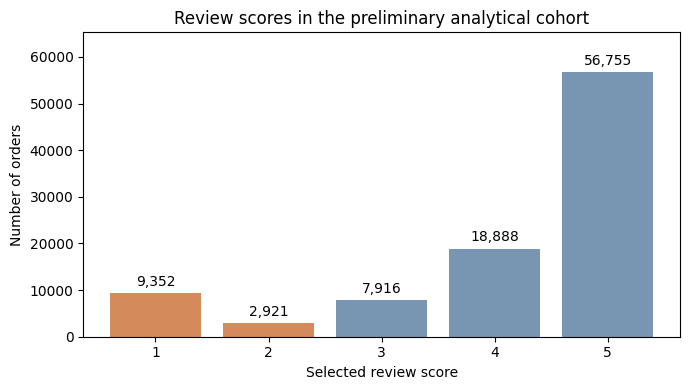

In [21]:
review_score_distribution = (
    analysis_df["review_score_latest"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
    .rename_axis("review_score")
    .reset_index(name="orders"))

review_score_distribution["percentage"] = (
    100 * review_score_distribution["orders"] / len(analysis_df))

display(review_score_distribution.round(2))

review_score_distribution.to_csv(
    TABLE_DIR / "review_score_distribution.csv",
    index=False,)

low_review_rate = analysis_df["y"].mean()

print(f"Low-review rate: {low_review_rate:.2%}")
print(
    "Accuracy from always predicting the majority class: "
    f"{max(low_review_rate, 1 - low_review_rate):.2%}")

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    review_score_distribution["review_score"],
    review_score_distribution["orders"],
    color=["#D48A5A", "#D48A5A", "#7895B2", "#7895B2", "#7895B2"],)

ax.bar_label(
    bars,
    labels=[
        f"{count:,}"
        for count in review_score_distribution["orders"]
    ],
    padding=3,)

ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel("Selected review score")
ax.set_ylabel("Number of orders")
ax.set_title("Review scores in the preliminary analytical cohort")
ax.set_ylim(0, review_score_distribution["orders"].max() * 1.15)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "review_score_distribution.png",
    dpi=300,
    bbox_inches="tight",)

plt.show()
plt.close(fig)

In [23]:
EXTREME_FIELDS = {
    "items_price_total": ("Total item value", "BRL"),
    "freight_value_total": ("Total freight charges", "BRL"),
    "freight_to_items_value_ratio": ("Freight-to-item-value ratio", "Ratio"),
    "total_delivery_duration_days": ("Total delivery duration", "Days"),
    "seller_customer_distance_km_item_mean": (
        "Mean customer-seller distance", "km"
    ),}

extreme_value_summary = pd.DataFrame([
    {
        "measurement": label,
        "unit": unit,
        "observed_orders": int(analysis_df[column].notna().sum()),
        "minimum": analysis_df[column].min(),
        "median": analysis_df[column].median(),
        "percentile_99": analysis_df[column].quantile(0.99),
        "maximum": analysis_df[column].max(),
        "zero_values": int(analysis_df[column].eq(0).sum()),
        "negative_values": int(analysis_df[column].lt(0).sum()),
    }
    for column, (label, unit) in EXTREME_FIELDS.items()])

display(extreme_value_summary.round(3))

extreme_value_summary.to_csv(
    TABLE_DIR / "extreme_value_summary.csv",
    index=False,)

,measurement,unit,observed_orders,minimum,median,percentile_99,maximum,zero_values,negative_values
0,Total item value,BRL,95832,0.850,86.250,990.000,13440.000,0,0
1,Total freight charges,BRL,95832,0.000,17.160,104.111,1794.960,335,0
2,Freight-to-item-value ratio,Ratio,95832,0.000,0.224,1.455,21.447,335,0
3,Total delivery duration,Days,95824,0.533,10.206,45.853,208.352,0,0
4,Mean customer-seller distance,km,95357,0.000,433.805,2482.958,8677.911,22,0


In [25]:
extreme_examples = []

for column, (label, unit) in EXTREME_FIELDS.items():
    largest = analysis_df.nlargest(5, column)[
        [
            "order_id",
            "customer_state",
            "item_count",
            "seller_count",
            "review_score_latest",
            column,
        ]].copy()

    largest = largest.rename(columns={column: "measurement_value"})
    largest.insert(0, "measurement", label)
    largest.insert(1, "unit", unit)

    extreme_examples.append(largest)

extreme_order_examples = pd.concat(
    extreme_examples,
    ignore_index=True,)

display(extreme_order_examples.round(3))

extreme_order_examples.to_csv(
    TABLE_DIR / "extreme_order_examples.csv",
    index=False,)

,measurement,unit,order_id,customer_state,item_count,seller_count,review_score_latest,measurement_value
0,Total item value,BRL,03caa2c082116e1d31e67e9ae3700499,RJ,8.0,1.0,1.0,13440.000
1,Total item value,BRL,736e1922ae60d0d6a89247b851902527,ES,4.0,1.0,1.0,7160.000
2,Total item value,BRL,0812eb902a67711a1cb742b3cdaa65ae,MS,1.0,1.0,5.0,6735.000
3,Total item value,BRL,f5136e38d1a14a4dbd87dff67da82701,SP,1.0,1.0,5.0,6499.000
4,Total item value,BRL,2cc9089445046817a7539d90805e6e5a,MG,6.0,1.0,1.0,5934.600
5,Total freight charges,BRL,cf4659487be50c0c317cff3564c4a840,PB,6.0,1.0,5.0,1794.960
6,Total freight charges,BRL,2455cbeb73fd04b170ca2504662f95ce,PR,6.0,1.0,1.0,1002.290
7,Total freight charges,BRL,cfed507ac357129f750f05a0d7d71b15,MA,3.0,1.0,1.0,711.330
8,Total freight charges,BRL,71dab1155600756af6de79de92e712e3,BA,11.0,1.0,3.0,626.640
9,Total freight charges,BRL,17784b9fbb37fb0bdc230d8ed6f6b355,BA,6.0,1.0,1.0,502.980


### Interpretation

Negative stage durations indicate inconsistent recorded event ordering and require investigation before those measurements enter a model.
They are not converted to absolute values or replaced with zero.

Reviews submitted before delivery can reflect dissatisfaction during a delay because surveys may be sent when the estimated date becomes due. They are not automatically recording errors.

Low reviews are the minority outcome, so majority-class accuracy is an inadequate measure of analytical usefulness.

Large monetary amounts, freight ratios, and delivery durations may be legitimate. Extreme distances require geographic investigation.
Influential observations can only be assessed relative to a fitted model, extreme values alone do not establish influence.

No records are excluded or winsorized in this section.

## 4. Additional Data Quality Checks

We examine geographic plausibility, field-specific zero values, payment reconciliation differences, and sparse product categories.

Diagnostic flags are retained for investigation rather than used as automatic exclusion rules.

In [26]:
quality_source_files = {
    "geo_raw": "olist_geolocation_dataset.csv",
    "products_raw": "olist_products_dataset.csv",
    "payments_raw": "olist_order_payments_dataset.csv",
    "items_raw": "olist_order_items_dataset.csv",}

for filename in quality_source_files.values():
    path = RAW_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f"Missing source file: {path}")

geo_raw = pd.read_csv(
    RAW_DIR / quality_source_files["geo_raw"],
    dtype={"geolocation_zip_code_prefix": "string"},)

products_raw = pd.read_csv(
    RAW_DIR / quality_source_files["products_raw"])

payments_raw = pd.read_csv(
    RAW_DIR / quality_source_files["payments_raw"])

items_raw = pd.read_csv(
    RAW_DIR / quality_source_files["items_raw"])

In [27]:
coordinates_present = (
    geo_raw["geolocation_lat"].notna()
    & geo_raw["geolocation_lng"].notna())

globally_valid = (
    coordinates_present
    & geo_raw["geolocation_lat"].between(-90, 90)
    & geo_raw["geolocation_lng"].between(-180, 180))

inside_brazil_screen = (
    geo_raw["geolocation_lat"].between(-34, 6)
    & geo_raw["geolocation_lng"].between(-74, -34))

outside_brazil_screen = globally_valid & ~inside_brazil_screen

geographic_quality_summary = pd.DataFrame([
    {"check": "Original geographic rows", "count": len(geo_raw)},
    {
        "check": "Rows with missing coordinates",
        "count": int((~coordinates_present).sum()),
    },
    {
        "check": "Nonmissing rows outside global bounds",
        "count": int((coordinates_present & ~globally_valid).sum()),
    },
    {
        "check": "Globally valid rows outside rough Brazil bounds",
        "count": int(outside_brazil_screen.sum()),
    },])

display(geographic_quality_summary)

geographic_quality_summary.to_csv(
    TABLE_DIR / "geographic_quality_summary.csv",
    index=False,)

suspicious_coordinates = geo_raw.loc[
    outside_brazil_screen].copy()

display(suspicious_coordinates.head(10))

suspicious_coordinates.to_csv(
    TABLE_DIR / "geographic_rows_outside_brazil_screen.csv",
    index=False,)

,check,count
0,Original geographic rows,1000163
1,Rows with missing coordinates,0
2,Nonmissing rows outside global bounds,0
3,Globally valid rows outside rough Brazil bounds,42


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
387565,18243,28.008978,-15.536867,bom retiro da esperanca,SP
513631,28165,41.614052,-8.411675,vila nova de campos,RJ
513643,28155,-34.586422,-58.732101,santa maria,RJ
513754,28155,42.439286,13.820214,santa maria,RJ
514429,28333,38.381672,-6.328200,raposo,RJ
516682,28595,43.684961,-7.411080,portela,RJ
538512,29654,29.409252,-98.484121,santo antônio do canaã,ES
538557,29654,21.657547,-101.466766,santo antonio do canaa,ES
585242,35179,25.995203,-98.078544,santana do paraíso,MG
585260,35179,25.995245,-98.078533,santana do paraiso,MG


In [28]:
ZERO_CHECKS = [
    ("products", products_raw, "product_weight_g"),
    ("products", products_raw, "product_length_cm"),
    ("products", products_raw, "product_height_cm"),
    ("products", products_raw, "product_width_cm"),
    ("payments", payments_raw, "payment_installments"),
    ("payments", payments_raw, "payment_value"),
    ("items", items_raw, "price"),
    ("items", items_raw, "freight_value"),]

zero_value_summary = pd.DataFrame([
    {
        "table": table_name,
        "field": column,
        "source_rows": len(table),
        "missing": int(table[column].isna().sum()),
        "zero": int(table[column].eq(0).sum()),
        "negative": int(table[column].lt(0).sum()),
    }
    for table_name, table, column in ZERO_CHECKS])

display(zero_value_summary)

zero_value_summary.to_csv(
    TABLE_DIR / "source_zero_negative_checks.csv",
    index=False,)

print(
    "Preliminary cohort orders with zero total freight:",
    int(analysis_df["freight_value_total"].eq(0).sum()),)

,table,field,source_rows,missing,zero,negative
0,products,product_weight_g,32951,2,4,0
1,products,product_length_cm,32951,2,0,0
2,products,product_height_cm,32951,2,0,0
3,products,product_width_cm,32951,2,0,0
4,payments,payment_installments,103886,0,2,0
5,payments,payment_value,103886,0,9,0
6,items,price,112650,0,0,0
7,items,freight_value,112650,0,383,0


Preliminary cohort orders with zero total freight: 335


In [29]:
money_columns = [
    "payment_value_total",
    "items_price_total",
    "freight_value_total",]

comparable_money = df[money_columns].notna().all(axis=1)

payment_reconciliation = df.loc[
    comparable_money,
    ["order_id", "order_status", *money_columns],].copy()

payment_reconciliation["items_plus_freight"] = (
    payment_reconciliation["items_price_total"]
    + payment_reconciliation["freight_value_total"])

payment_reconciliation["payment_difference_brl"] = (
    payment_reconciliation["payment_value_total"]
    - payment_reconciliation["items_plus_freight"])

# Small epsilon avoids treating floating-point noise as > R$0.01.
payment_reconciliation["difference_over_one_cent"] = (
    payment_reconciliation["payment_difference_brl"]
    .abs()
    .gt(0.01 + 1e-9))

payment_difference_summary = pd.DataFrame([
    {
        "metric": "Orders with comparable monetary totals",
        "value": len(payment_reconciliation),
    },
    {
        "metric": "Orders differing by more than BRL 0.01",
        "value": int(
            payment_reconciliation["difference_over_one_cent"].sum()),},])

display(payment_difference_summary)

payment_difference_summary.to_csv(
    TABLE_DIR / "payment_difference_summary.csv",
    index=False,)

payment_discrepancies = (
    payment_reconciliation.loc[
        payment_reconciliation["difference_over_one_cent"]
    ]
    .assign(
        absolute_difference=lambda x: x["payment_difference_brl"].abs()
    )
    .sort_values("absolute_difference", ascending=False))

display(payment_discrepancies.head(10).round(2))

payment_discrepancies.to_csv(
    TABLE_DIR / "payment_discrepancy_orders.csv",
    index=False,)

,metric,value
0,Orders with comparable monetary totals,98665
1,Orders differing by more than BRL 0.01,303


,order_id,order_status,payment_value_total,items_price_total,freight_value_total,items_plus_freight,payment_difference_brl,difference_over_one_cent,absolute_difference
11791,ce6d150fb29ada17d2082f4847107665,delivered,1586.47,1299.00,104.66,1403.66,182.81,True,182.81
48686,6e5fe7366a2e1bfbf3257dba0af1267f,delivered,406.92,179.19,108.72,287.91,119.01,True,119.01
70865,70b742795bc441e94a44a084b6d9ce7a,delivered,578.82,269.99,196.94,466.93,111.89,True,111.89
33150,996c7e73600ad3723e8627ab7bef81e4,delivered,664.43,559.90,28.00,587.90,76.53,True,76.53
52985,70b7e94ea46d3e8b5bc12a50186edaf0,delivered,274.84,167.88,45.27,213.15,61.69,True,61.69
85434,bc2c82b0ef78d2252b6176d1972db7c9,delivered,303.02,165.00,77.01,242.01,61.01,True,61.01
94304,af9ffff2ce6b3defd34fd4c78857a379,delivered,466.97,395.65,17.52,413.17,53.80,True,53.80
31661,262118ce178bb3e4590a3adcf6d62e6b,delivered,126.12,119.80,57.94,177.74,-51.62,True,51.62
68811,bfdb5bbb06458d600a33d61f5f287472,delivered,394.36,297.00,51.93,348.93,45.43,True,45.43
8548,8d9c0dc8d5a2ce804f6b925d8f8e6c1d,delivered,293.89,209.80,44.65,254.45,39.44,True,39.44


In [31]:
category_quality_summary = (
    analysis_df.groupby(
        "primary_product_category",
        dropna=False,
    )
    .agg(
        orders=("order_id", "size"),
        low_reviews=("y", "sum"),
        low_review_rate=("y", "mean"),
    )
    .reset_index())

category_quality_summary["low_review_rate_pct"] = (
    100 * category_quality_summary.pop("low_review_rate"))

category_quality_summary["missing_category"] = (
    category_quality_summary["primary_product_category"].isna())

category_quality_summary["fewer_than_30_orders"] = (
    category_quality_summary["orders"].lt(30)
    & ~category_quality_summary["missing_category"])

observed_categories = category_quality_summary.loc[
    ~category_quality_summary["missing_category"]]

print("Observed primary categories:", len(observed_categories))
print(
    "Observed categories with fewer than 30 orders:",
    int(observed_categories["fewer_than_30_orders"].sum()),)

display(
    category_quality_summary
    .sort_values("orders")
    .head(15)
    .round(2))

category_quality_summary.to_csv(
    TABLE_DIR / "category_quality_summary.csv",
    index=False,)

assert category_quality_summary["orders"].sum() == len(analysis_df)

Observed primary categories: 73
Observed categories with fewer than 30 orders: 11


,primary_product_category,orders,low_reviews,low_review_rate_pct,missing_category,fewer_than_30_orders
67,seguros_e_servicos,2,1,50.00,False,True
37,fashion_roupa_infanto_juvenil,5,0,0.00,False,True
60,pc_gamer,6,1,16.67,False,True
46,la_cuisine,11,1,9.09,False,True
17,cds_dvds_musicais,12,0,0.00,False,True
65,portateis_cozinha_e_preparadores_de_alimentos,13,3,23.08,False,True
15,casa_conforto_2,22,4,18.18,False,True
4,artes_e_artesanato,23,3,13.04,False,True
42,fraldas_higiene,25,3,12.00,False,True
35,fashion_esporte,25,2,8.00,False,True


### Interpretation

Global coordinate validity does not establish geographic accuracy. The rough Brazil bounds flag records for inspection, not automatic removal.

Zero values require field-specific interpretation. Free freight may be legitimate, while zero product weights or installment counts need review.

Payment discrepancies are calculated only for orders with complete comparable totals, using a documented numerical tolerance. Their causes
are not established, so source amounts are not overwritten.

Sparse categories can produce unstable rates. The 30-order threshold is a diagnostic screen rather than a finalized modeling or exclusion rule. Missing categories remain separately identifiable.

## 5. Dependence Structure

Orders may share customers, sellers, products, periods, and locations. We summarize these relationships and examine contextual variation.

Shared structure and differences in group rates do not by themselves establish residual correlation or causal effects.

In [33]:
customer_order_counts = (
    analysis_df.groupby("customer_unique_id")["order_id"].nunique())

repeated_customers = customer_order_counts[
    customer_order_counts.gt(1)]

customer_dependence_summary = pd.DataFrame([
    {
        "metric": "Distinct customers",
        "value": len(customer_order_counts),
    },
    {
        "metric": "Customers with multiple eligible orders",
        "value": len(repeated_customers),
    },
    {
        "metric": "Orders belonging to repeated customers",
        "value": int(repeated_customers.sum()),
    },
    {
        "metric": "Maximum eligible orders per customer",
        "value": int(customer_order_counts.max()),
    },])

display(customer_dependence_summary)

customer_dependence_summary.to_csv(
    TABLE_DIR / "customer_dependence_summary.csv",
    index=False,)

,metric,value
0,Distinct customers,92755
1,Customers with multiple eligible orders,2764
2,Orders belonging to repeated customers,5841
3,Maximum eligible orders per customer,15


In [35]:
eligible_order_ids = analysis_df["order_id"]

eligible_items = items_raw.loc[
    items_raw["order_id"].isin(eligible_order_ids)].copy()

seller_order_links = (
    eligible_items[["order_id", "seller_id"]]
    .drop_duplicates())

product_order_links = (
    eligible_items[["order_id", "product_id"]]
    .drop_duplicates())

seller_order_counts = (
    seller_order_links.groupby("seller_id")["order_id"].nunique())

product_order_counts = (
    product_order_links.groupby("product_id")["order_id"].nunique())

entity_dependence_summary = pd.DataFrame([
    {
        "entity": label,
        "distinct_entities": len(counts),
        "entities_with_multiple_orders": int(counts.gt(1).sum()),
        "maximum_orders_per_entity": int(counts.max()),
    }
    for label, counts in [
        ("Customer", customer_order_counts),
        ("Seller", seller_order_counts),
        ("Product", product_order_counts), ]])

display(entity_dependence_summary)

entity_dependence_summary.to_csv(
    TABLE_DIR / "entity_dependence_summary.csv",
    index=False,)

print(
    "Multi-seller orders:",
    int(analysis_df["seller_count"].gt(1).sum()),)

,entity,distinct_entities,entities_with_multiple_orders,maximum_orders_per_entity
0,Customer,92755,2764,15
1,Seller,2965,2431,1805
2,Product,32072,13025,448


Multi-seller orders: 1261


In [37]:
seller_outcome_links = seller_order_links.merge(
    analysis_df[["order_id", "y"]],
    on="order_id",
    how="left",
    validate="many_to_one",)

assert seller_outcome_links["y"].notna().all()

seller_rate_summary = (
    seller_outcome_links.groupby("seller_id")
    .agg(
        orders=("order_id", "size"),
        low_reviews=("y", "sum"),
        low_review_rate=("y", "mean"),
    )
    .reset_index())

seller_rate_summary["low_review_rate_pct"] = (
    100 * seller_rate_summary.pop("low_review_rate"))

large_seller_groups = seller_rate_summary.loc[
    seller_rate_summary["orders"].ge(100)].copy()

print("Sellers linked to at least 100 orders:", len(large_seller_groups))

display(
    large_seller_groups["low_review_rate_pct"]
    .describe()
    .to_frame("Low-review rate (%)")
    .round(2))

seller_rate_summary.to_csv(
    TABLE_DIR / "seller_rate_summary.csv",
    index=False,)

Sellers linked to at least 100 orders: 208


,Low-review rate (%)
count,208.00
mean,13.55
std,6.56
min,3.00
25%,9.67
50%,12.36
75%,16.34
max,59.81


In [39]:
monthly_summary = (
    analysis_df.groupby("order_purchase_month")
    .agg(
        orders=("order_id", "size"),
        low_reviews=("y", "sum"),
        low_review_rate=("y", "mean"),
        delivery_timing_observed=("delivered_late", "count"),
        late_orders=("delivered_late", "sum"),
    )
    .sort_index())

monthly_summary["low_review_rate_pct"] = (
    100 * monthly_summary.pop("low_review_rate"))

monthly_summary["late_delivery_rate_pct"] = (
    100
    * monthly_summary["late_orders"]
    / monthly_summary["delivery_timing_observed"].replace(0, np.nan))

display(monthly_summary.round(2))

monthly_summary.to_csv(
    TABLE_DIR / "monthly_outcome_summary.csv",
    index=True,)

,orders,low_reviews,delivery_timing_observed,late_orders,low_review_rate_pct,late_delivery_rate_pct
order_purchase_month,,,,,,
2016-09,1,1,1,1,100.00,100.0
2016-10,262,43,262,2,16.41,0.76
2016-12,1,0,1,0,0.00,0.0
2017-01,741,89,741,21,12.01,2.83
2017-02,1643,182,1643,42,11.08,2.56
2017-03,2527,284,2527,113,11.24,4.47
2017-04,2290,296,2290,147,12.93,6.42
2017-05,3518,354,3517,99,10.06,2.81
2017-06,3111,334,3111,92,10.74,2.96


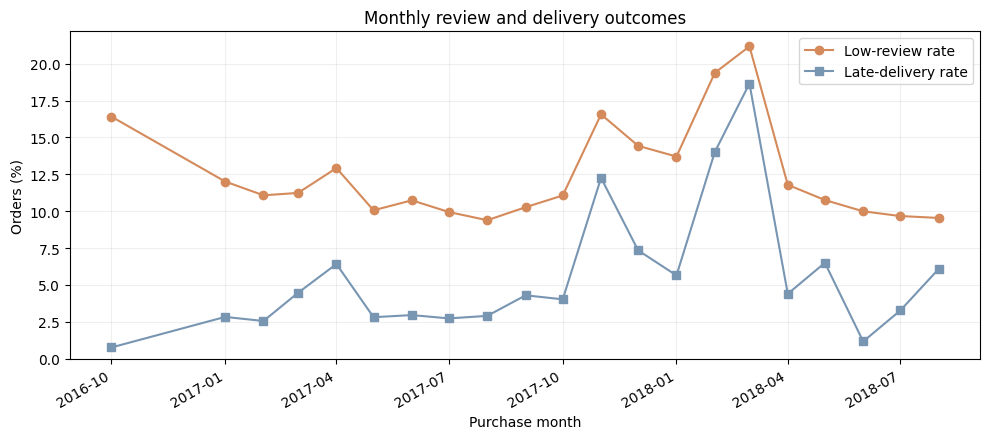

In [41]:
monthly_plot = monthly_summary.loc[
    monthly_summary["orders"].ge(100)].copy()

# Actual calendar dates preserve gaps between months.
plot_dates = pd.to_datetime(
    monthly_plot.index.astype(str),
    format="%Y-%m",)

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(
    plot_dates,
    monthly_plot["low_review_rate_pct"].to_numpy(dtype=float),
    marker="o",
    label="Low-review rate",
    color="#D48A5A",)

ax.plot(
    plot_dates,
    monthly_plot["late_delivery_rate_pct"].to_numpy(dtype=float),
    marker="s",
    label="Late-delivery rate",
    color="#7895B2",)

ax.set_xlabel("Purchase month")
ax.set_ylabel("Orders (%)")
ax.set_title("Monthly review and delivery outcomes")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.2)
ax.legend()

fig.autofmt_xdate()
fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "monthly_review_delivery_rates.png",
    dpi=300,
    bbox_inches="tight",)

plt.show()
plt.close(fig)

In [43]:
state_summary = (
    analysis_df.groupby("customer_state", dropna=False)
    .agg(
        orders=("order_id", "size"),
        low_reviews=("y", "sum"),
        low_review_rate=("y", "mean"),
    )
    .reset_index())

state_summary["low_review_rate_pct"] = (
    100 * state_summary.pop("low_review_rate"))

state_summary["order_share_pct"] = (
    100 * state_summary["orders"] / len(analysis_df))

state_summary = state_summary.sort_values(
    "orders",
    ascending=False,)

display(state_summary.round(2))

state_summary.to_csv(
    TABLE_DIR / "customer_state_summary.csv",
    index=False,)

assert state_summary["orders"].sum() == len(analysis_df)

,customer_state,orders,low_reviews,low_review_rate_pct,order_share_pct
25,SP,40273,4304,10.69,42.02
18,RJ,12211,2238,18.33,12.74
10,MG,11285,1326,11.75,11.78
22,RS,5327,635,11.92,5.56
17,PR,4900,533,10.88,5.11
23,SC,3519,457,12.99,3.67
4,BA,3229,549,17.00,3.37
6,DF,2070,274,13.24,2.16
7,ES,1969,272,13.81,2.05
8,GO,1946,256,13.16,2.03


In [45]:
dossier_state_table = (
    state_summary.set_index("customer_state")
    .loc[
        ["SP", "RJ", "MG", "BA", "CE"],
        ["orders", "low_review_rate_pct"],
    ]
    .reset_index())

display(dossier_state_table.round(2))

dossier_state_table.to_csv(
    TABLE_DIR / "dossier_state_comparison.csv",
    index=False,)

,customer_state,orders,low_review_rate_pct
0,SP,40273,10.69
1,RJ,12211,18.33
2,MG,11285,11.75
3,BA,3229,17.00
4,CE,1273,17.12


### Interpretation

Repeated customers and shared sellers and products create overlapping groups. Multi-seller orders make the structure cross-classified rather
than purely nested within one seller.

Monthly and state-level rates vary, but these differences may reflect order composition and shared operating conditions. They do not establish serial or spatial residual correlation.

Seller groups overlap for multi-seller orders, so their counts should not be summed as a total number of independent orders.

Temporal validation will assess later operating periods. Grouped checks will address separate claims about unseen customers or sellers.
Uncertainty estimation must consider the dependence supported by subsequent analysis.

## 6. Exploratory Data Analysis

This section examines how dissatisfaction varies across delivery delays, order complexity, and freight-to-item-value ratios.

The analysis uses delivered orders with a valid selected review score. Dissatisfaction is defined as a selected review score of 1 or 2.

These comparisons are descriptive and unadjusted. They do not establish causal effects, because the groups may differ in other characteristics.

In [47]:
delay_labels = [
    "On time or early",
    "1–3 days late",
    "4–7 days late",
    "More than 7 days late",]

delay_eda = analysis_df.loc[
    analysis_df["delivery_delay_days"].notna()].copy()

delay_eda["delay_group"] = pd.cut(
    delay_eda["delivery_delay_days"].astype(float),
    bins=[-np.inf, 0, 3, 7, np.inf],
    labels=delay_labels,)

delay_summary = (
    delay_eda.groupby("delay_group", observed=False)
    .agg(
        order_count=("order_id", "size"),
        dissatisfied_orders=("y", "sum"),
    )
    .reindex(delay_labels))

delay_summary["dissatisfaction_rate_pct"] = (
    100
    * delay_summary["dissatisfied_orders"]
    / delay_summary["order_count"].replace(0, np.nan))

assert delay_summary["order_count"].sum() == len(delay_eda)

display(delay_summary.round(2))

print(
    "Orders excluded from this comparison because delay is unknown:",
    analysis_df["delivery_delay_days"].isna().sum(),)

delay_summary.to_csv(
    TABLE_DIR / "delivery_delay_group_summary.csv",
    index=True,)

,order_count,dissatisfied_orders,dissatisfaction_rate_pct
delay_group,,,
On time or early,89443,8289,9.27
1–3 days late,1852,595,32.13
4–7 days late,1748,1183,67.68
More than 7 days late,2781,2205,79.29


Orders excluded from this comparison because delay is unknown: 8


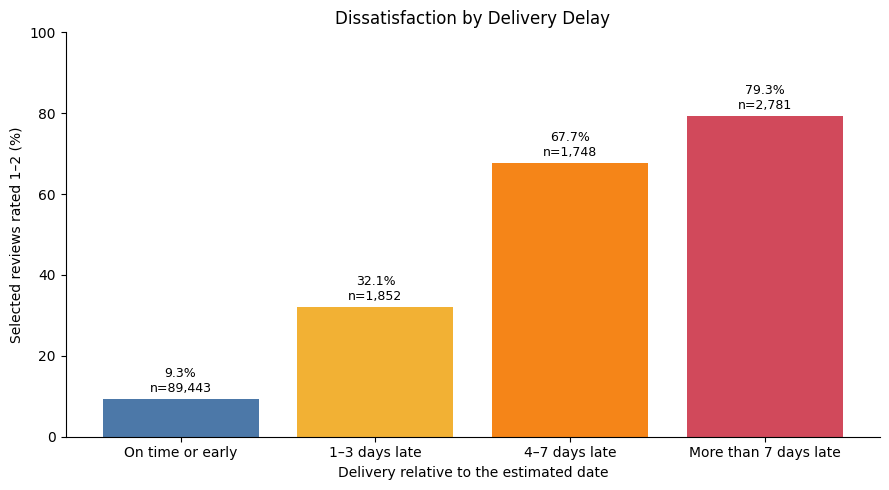

In [49]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    delay_summary.index.astype(str),
    delay_summary["dissatisfaction_rate_pct"],
    color=["#4C78A8", "#F2B134", "#F58518", "#D1495B"],)

for bar, rate, count in zip(
    bars,
    delay_summary["dissatisfaction_rate_pct"],
    delay_summary["order_count"],):
    if pd.notna(rate):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{rate:.1f}%\nn={count:,}",
            ha="center",
            va="bottom",
            fontsize=9,)

ax.set(
    title="Dissatisfaction by Delivery Delay",
    xlabel="Delivery relative to the estimated date",
    ylabel="Selected reviews rated 1–2 (%)",
    ylim=(0, 100),)

ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "dissatisfaction_by_delivery_delay.png",
    dpi=300,
    bbox_inches="tight",)

plt.show()
plt.close(fig)

### 6.1 Review-Timing Sensitivity Analysis

The delivery-delay comparison is repeated for orders whose selected review answer timestamp is on or after actual delivery.

This restriction changes the population being analysed. It may exclude customers who reviewed an order while still waiting for delivery.
Therefore, the restricted results are a sensitivity analysis rather than a replacement for the full-cohort results.

In [51]:
def summarize_lateness(frame, cohort_name):
    usable = frame.loc[
        frame["delivery_delay_days"].notna()].copy()

    usable["delivery_group"] = np.where(
        usable["delivery_delay_days"].gt(0),
        "Late",
        "On time or early",)

    result = (
        usable.groupby("delivery_group")
        .agg(
            order_count=("order_id", "size"),
            dissatisfied_orders=("y", "sum"),
        )
        .reindex(["On time or early", "Late"])
        .reset_index())

    result.insert(0, "review_cohort", cohort_name)

    result["dissatisfaction_rate_pct"] = (
        100
        * result["dissatisfied_orders"]
        / result["order_count"].replace(0, np.nan))

    return result


known_review_and_delivery = (
    analysis_df["review_answer_timestamp"].notna()
    & analysis_df["order_delivered_customer_date"].notna())

post_delivery_mask = (
    known_review_and_delivery
    & analysis_df["review_answer_timestamp"].ge(
        analysis_df["order_delivered_customer_date"]))

post_delivery_df = analysis_df.loc[post_delivery_mask].copy()

review_timing_sensitivity = pd.concat(
    [
        summarize_lateness(
            analysis_df,
            "All selected reviews",),
        summarize_lateness(
            post_delivery_df,
            "Reviews answered on or after delivery",),],
    ignore_index=True,)

display(review_timing_sensitivity.round(2))

review_timing_sensitivity.to_csv(
    TABLE_DIR / "review_timing_lateness_sensitivity.csv",
    index=False,)

,review_cohort,delivery_group,order_count,dissatisfied_orders,dissatisfaction_rate_pct
0,All selected reviews,On time or early,89443,8289,9.27
1,All selected reviews,Late,6381,3983,62.42
2,Reviews answered on or after delivery,On time or early,89263,8258,9.25
3,Reviews answered on or after delivery,Late,1908,371,19.44


In [52]:
complexity_eda = analysis_df.copy()

complexity_eda["item_group"] = pd.cut(
    complexity_eda["item_count"],
    bins=[0, 1, 2, np.inf],
    labels=["1 item", "2 items", "3 or more items"],)

complexity_eda["seller_group"] = pd.Series(
    pd.NA,
    index=complexity_eda.index,
    dtype="string",)

complexity_eda.loc[
    complexity_eda["seller_count"].eq(1),
    "seller_group",] = "Single seller"

complexity_eda.loc[
    complexity_eda["seller_count"].gt(1),
    "seller_group",] = "Multiple sellers"


def summarize_group(frame, group_column):
    result = (
        frame.groupby(group_column, observed=True)
        .agg(
            order_count=("order_id", "size"),
            dissatisfied_orders=("y", "sum"),))

    result["dissatisfaction_rate_pct"] = (
        100
        * result["dissatisfied_orders"]
        / result["order_count"].replace(0, np.nan))
    return result

item_complexity_summary = summarize_group(
    complexity_eda,
    "item_group",)

seller_complexity_summary = summarize_group(
    complexity_eda,
    "seller_group",).reindex(["Single seller", "Multiple sellers"])

display(item_complexity_summary.round(2))
display(seller_complexity_summary.round(2))

item_complexity_summary.to_csv(
    TABLE_DIR / "item_complexity_summary.csv",
    index=True,)

seller_complexity_summary.to_csv(
    TABLE_DIR / "seller_complexity_summary.csv",
    index=True,)

,order_count,dissatisfied_orders,dissatisfaction_rate_pct
item_group,,,
1 item,86304,9725,11.27
2 items,7319,1859,25.40
3 or more items,2209,689,31.19


,order_count,dissatisfied_orders,dissatisfaction_rate_pct
seller_group,,,
Single seller,94571,11678,12.35
Multiple sellers,1261,595,47.18


In [53]:
freight_labels = [
    "≤10%",
    ">10–25%",
    ">25–50%",
    ">50–100%",
    ">100%",]

freight_eda = analysis_df.loc[
    analysis_df["freight_to_items_value_ratio"].notna()
    & np.isfinite(analysis_df["freight_to_items_value_ratio"])
    & analysis_df["freight_to_items_value_ratio"].ge(0)].copy()

freight_eda["freight_ratio_group"] = pd.cut(
    freight_eda["freight_to_items_value_ratio"],
    bins=[-np.inf, 0.10, 0.25, 0.50, 1.00, np.inf],
    labels=freight_labels,)

freight_ratio_summary = summarize_group(
    freight_eda,
    "freight_ratio_group",).reindex(freight_labels)

assert freight_ratio_summary["order_count"].sum() == len(freight_eda)

display(freight_ratio_summary.round(2))

print(
    "Orders excluded because freight ratio is missing or invalid:",
    len(analysis_df) - len(freight_eda),)

freight_ratio_summary.to_csv(
    TABLE_DIR / "freight_ratio_summary.csv",
    index=True,)

,order_count,dissatisfied_orders,dissatisfaction_rate_pct
freight_ratio_group,,,
≤10%,15150,1883,12.43
>10–25%,37910,4692,12.38
>25–50%,27593,3632,13.16
>50–100%,12124,1597,13.17
>100%,3055,469,15.35


Orders excluded because freight ratio is missing or invalid: 0


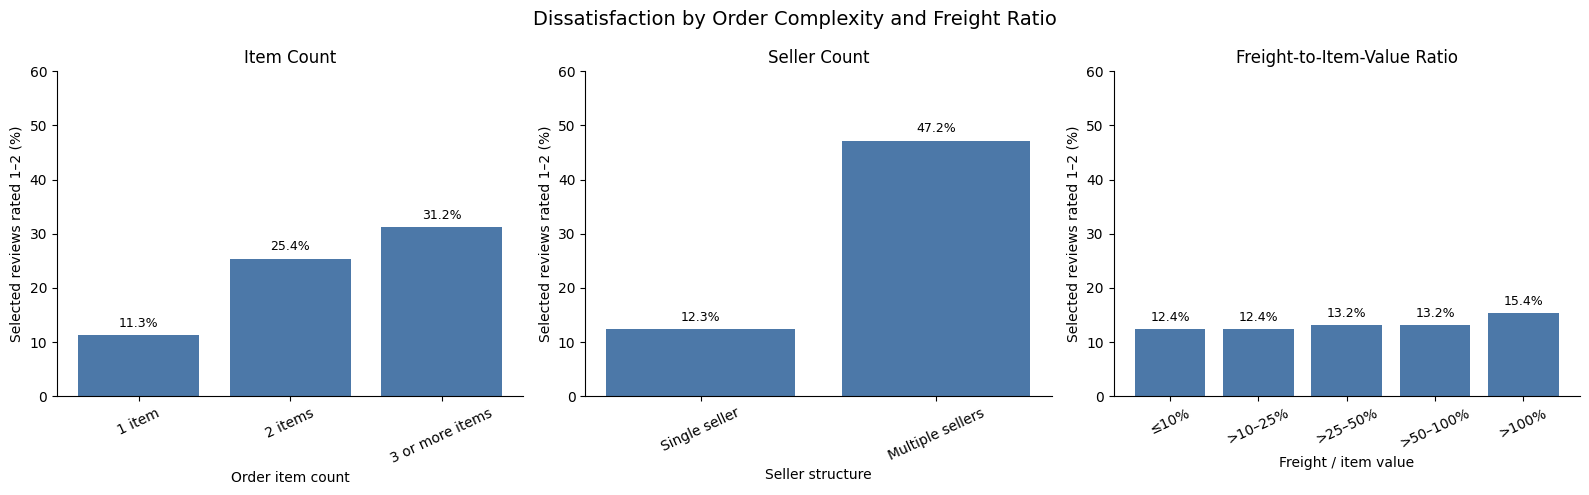

In [55]:
plot_specs = [
    (
        item_complexity_summary,
        "Item Count",
        "Order item count",
    ),
    (
        seller_complexity_summary,
        "Seller Count",
        "Seller structure",
    ),
    (
        freight_ratio_summary,
        "Freight-to-Item-Value Ratio",
        "Freight / item value",),]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (summary, title, xlabel) in zip(axes, plot_specs):
    rates = summary["dissatisfaction_rate_pct"]

    bars = ax.bar(
        summary.index.astype(str),
        rates,
        color="#4C78A8",)

    for bar, rate in zip(bars, rates):
        if pd.notna(rate):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                rate + 1,
                f"{rate:.1f}%",
                ha="center",
                va="bottom",
                fontsize=9,)

    ax.set(
        title=title,
        xlabel=xlabel,
        ylabel="Selected reviews rated 1–2 (%)",
        ylim=(0, 60),)

    ax.tick_params(axis="x", labelrotation=25)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Dissatisfaction by Order Complexity and Freight Ratio",
    fontsize=14,)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "complexity_and_freight_dissatisfaction.png",
    dpi=300,
    bbox_inches="tight",)
plt.show()
plt.close(fig)

### 6.2 Interpretation

Dissatisfaction is higher among orders with longer delivery delays, more order items, and multiple sellers. The variation across freight
ratio groups is comparatively modest.

The delivery-delay association changes substantially when the analysis is restricted to reviews answered on or after delivery. This highlights the importance of review timing and cohort definition.

These comparisons identify candidate areas for operational investigation. They do not isolate the contribution of each factor or demonstrate that changing a factor would improve customer satisfaction.

## 7. Proposed Features and Leakage Controls

The planned model supports retrospective operational analysis of completed orders. Candidate predictors include delivery delay, promised
delivery duration, approval and fulfilment-stage durations, item count, seller count, item value, freight-to-item-value ratio, customer state, product category, product dimensions, and estimated seller-to-customer distance.

Actual delivery information is appropriate for this retrospective setting. A model intended for prediction at order placement would
require a separate feature set containing only information available at that time.

Review scores, review text, review timestamps, and review-derived summaries will not be used as predictors. The selected review score
will be used only to define dissatisfaction. Identifiers will be retained for auditing and dependence checks rather than included
as model features.

Missing-value imputation, scaling, encoding, and any data-dependent feature selection will be fitted using training data only. Negative
delivery delays will be retained because they represent early delivery, invalid physical measurements and negative fulfilment-stage durations will be handled through documented validity rules.

Feature selection and preprocessing remain provisional at Milestone 2.

## 8. Preliminary Validation Design

The intended generalisation population is later delivered and reviewed orders within a comparable Olist operating environment. Generalisation to unreviewed orders, cancelled orders, other platforms, or present-day operations is not established by this dataset.

The primary validation strategy will use earlier purchase periods for training and later purchase periods for evaluation. Exact cutoffs will
be selected after checking sample sizes and follow-up availability. Training records must have both the required fulfilment information
and the selected review available before the relevant fitting cutoff.

Customer overlap across periods will be reported. A supplementary customer-disjoint evaluation will examine performance on customers
absent from the training data. Seller and product overlap will also be documented, because orders sharing these entities may have
dependent outcomes. A temporal split alone does not remove this dependence.

The full reviewed cohort and the subset with reviews answered on or after delivery will be examined separately as a sensitivity analysis.
They represent different populations and will not be treated as interchangeable estimates.

Because the full dataset has already been explored descriptively, any later holdout drawn from it will be described as an exploratory
internal evaluation rather than a completely untouched confirmation sample. Final validation is deferred to a later milestone.

## 9. Baseline Strategy and Planned Evaluation

Two baselines are proposed.

The first is a constant-probability baseline that assigns every evaluation order the dissatisfaction prevalence estimated from the
training data. It provides a reference for assessing whether operational features add predictive information.

The second is a regularised logistic regression using the proposed operational features. It provides a transparent initial model for
comparing later, more flexible methods. Numeric imputation and scaling, and categorical imputation and encoding, will be implemented within
a preprocessing pipeline fitted only on training data.

Planned evaluation will include average precision, ROC-AUC, Brier score, and calibration plots. Average precision will be interpreted
alongside the dissatisfaction prevalence in the evaluation sample. Accuracy alone will not be used to judge performance because low
ratings are a minority outcome.

For operational prioritisation, precision and recall among a prespecified proportion of the highest-risk orders may also be
reported. Any capacity threshold will be chosen using operational assumptions or development data rather than optimised on the final
evaluation set.

Model associations and predictive performance will not be interpreted as evidence that an intervention causes improved satisfaction.
No predictive model is fitted at this milestone.

## 10. Milestone 2 Summary and Next Steps
The exploratory results identify delivery delay and order complexity as candidate areas for further investigation. Review-timing sensitivity
shows that the observed delivery-delay association depends substantially on the population included in the analysis.

The main unresolved issues are review-selection bias, review timing, dependence across customers and sellers, and the stability of
associations across periods. These limitations inform the proposed modelling and validation strategy.

Later work will finalise cohort and feature rules, implement the baselines, evaluate temporal and customer-disjoint performance, and
assess whether more flexible models provide useful improvements.

The present deliverable establishes the data evidence and analytical plan for Milestone 2; final model selection, tuning, and intervention
evaluation remain future work.